In [42]:
import pandas as pd

smarts_train_fp = "../../data/smarts/fraggnn_d3_ma_mi/smarts_train.csv"
smarts_train_df = pd.read_csv(smarts_train_fp)

smarts_val_fp = "../../data/smarts/fraggnn_d3_ma_mi/smarts_val.csv"
smarts_val_df = pd.read_csv(smarts_val_fp)

smarts_test_fp = "../../data/smarts/fraggnn_d3_ma_mi/smarts_test.csv"
smarts_test_df = pd.read_csv(smarts_test_fp)


#smarts_train_fp = "../../data/smarts/debug_tiny/smarts_train.csv"
#smarts_train_df = pd.read_csv(smarts_train_fp)

#smarts_val_fp = "../../data/smarts/debug_tiny/smarts_val.csv"
#smarts_val_df = pd.read_csv(smarts_val_fp)

#smarts_test_fp = "../../data/smarts/debug_tiny/smarts_test.csv"
#smarts_test_df = pd.read_csv(smarts_test_fp)

In [43]:
smarts_train_df.head(10)

In [ ]:
def get_smarts_df_stats(smarts_dict):
    """
    Generate statistics from a dictionary of {name: DataFrame}, 
    where each DataFrame contains 'prec_type', 'formula', and 'smiles' columns.

    Returns a summary DataFrame with:
    - Total and unique counts of formulas and SMILES per prec_type per dataset
    - Count of overlapping unique formulas and SMILES across prec_types in each dataset
    """
    summary_rows = []

    for name, df in smarts_dict.items():
        grouped = df.groupby('prec_type')
        formula_counts = grouped['formula'].count()
        smiles_counts = grouped['smiles'].count()
        unique_formulas = grouped['formula'].nunique()
        unique_smiles = grouped['smiles'].nunique()
        for prec_type in grouped.groups.keys():
            summary_rows.append({
                'dataset': name,
                'prec_type': prec_type,
                'formula_count': formula_counts[prec_type],
                'smiles_count': smiles_counts[prec_type],
                'unique_formulas': unique_formulas[prec_type],
                'unique_smiles': unique_smiles[prec_type]
            })

        # Overlap calculations using unique formulas/SMILES only
        formula_sets = grouped['formula'].apply(lambda x: set(x.unique()))
        smiles_sets = grouped['smiles'].apply(lambda x: set(x.unique()))

        overlapping_formulas = set.intersection(*formula_sets) if len(formula_sets) > 1 else set()
        overlapping_smiles = set.intersection(*smiles_sets) if len(smiles_sets) > 1 else set()

        summary_rows.append({
            'dataset': name,
            'prec_type': 'OVERLAP',
            'formula_count': len(overlapping_formulas),
            'smiles_count': len(overlapping_smiles),
            'unique_formulas': len(overlapping_formulas),
            'unique_smiles': len(overlapping_smiles)
        })

    return pd.DataFrame(summary_rows)


smarts_dict = {
    'train': smarts_train_df,
    'val': smarts_val_df,
    'test': smarts_test_df
}
get_smarts_df_stats(smarts_dict)

,dataset,prec_type,formula_count,smiles_count,unique_formulas,unique_smiles
0,train,[M+H]+,2497011,2497011,106500,972472
1,train,OVERLAP,0,0,0,0
2,val,[M+H]+,824715,824715,55413,362962
3,val,OVERLAP,0,0,0,0
4,test,[M+H]+,880071,880071,58303,389129
5,test,OVERLAP,0,0,0,0


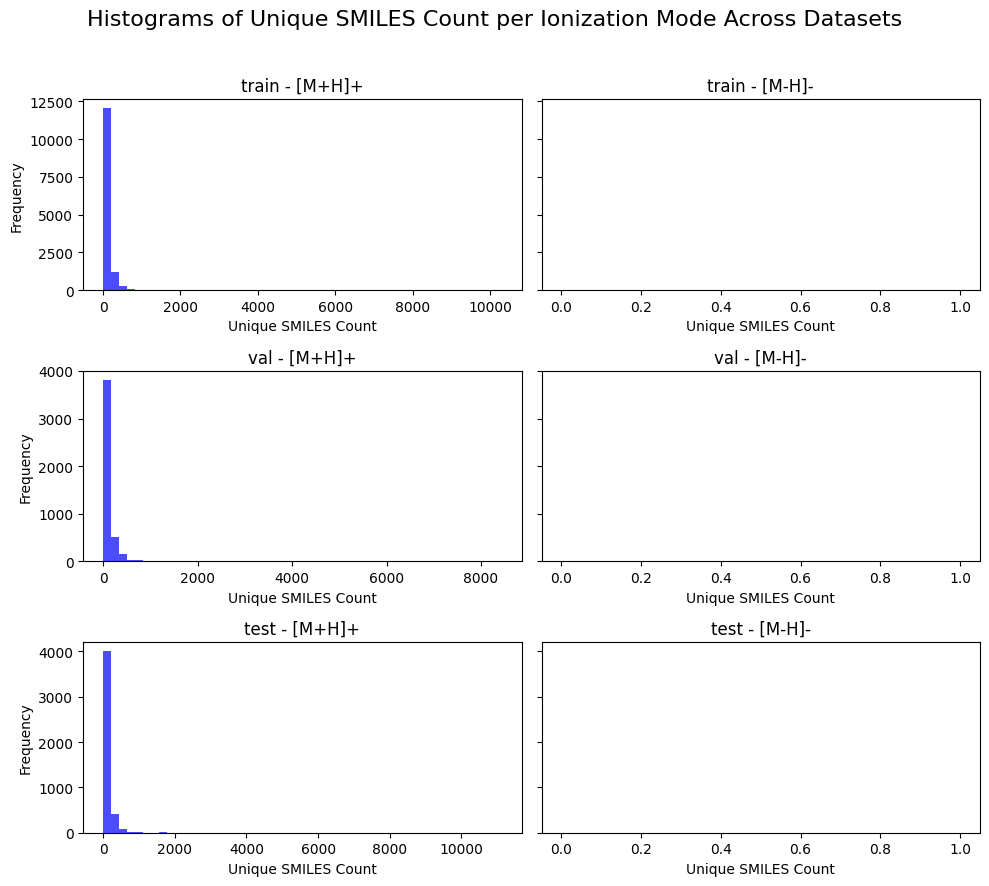

In [44]:
import matplotlib.pyplot as plt

def plot_unique_smiles_histograms(smarts_dict, smiles_col='smiles', mol_col='mol_smiles', prec_col='prec_type', bins=50):
    """
    Plots histograms of unique SMILES count per mol_smiles for each ionization mode ([M+H]+ and [M-H]-),
    across multiple datasets provided as a dictionary.

    Parameters:
        smarts_dict (dict): Dictionary of {name: DataFrame}, each containing precursor type, SMILES, and molecule columns.
        smiles_col (str): Column name for SMILES.
        mol_col (str): Column name for molecule identifier (e.g., canonical SMILES).
        prec_col (str): Column name for precursor type (e.g., [M+H]+ or [M-H]-).
        bins (int): Number of histogram bins.
    """
    n = len(smarts_dict)
    fig, axes = plt.subplots(nrows=n, ncols=2, figsize=(10, 3 * n), sharey='row')

    if n == 1:
        axes = [axes]  # ensure iterable even when 1 dataset

    for idx, (name, df) in enumerate(smarts_dict.items()):
        # Count unique SMILES per mol_smiles within each prec_type
        unique_counts = (
            df.groupby([prec_col, mol_col])[smiles_col]
            .nunique()
            .reset_index()
            .rename(columns={smiles_col: 'unique_smiles_count'})
        )

        mh_plus_data = unique_counts[unique_counts[prec_col] == '[M+H]+']
        mh_minus_data = unique_counts[unique_counts[prec_col] == '[M-H]-']

        ax1, ax2 = axes[idx]

        # [M+H]+ Histogram
        ax1.hist(mh_plus_data['unique_smiles_count'], bins=bins, color='blue', alpha=0.7)
        ax1.set_title(f'{name} - [M+H]+')
        ax1.set_xlabel('Unique SMILES Count')
        ax1.set_ylabel('Frequency')

        # [M-H]- Histogram
        ax2.hist(mh_minus_data['unique_smiles_count'], bins=bins, color='orange', alpha=0.7)
        ax2.set_title(f'{name} - [M-H]-')
        ax2.set_xlabel('Unique SMILES Count')

    plt.suptitle('Histograms of Unique SMILES Count per Ionization Mode Across Datasets', fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

plot_unique_smiles_histograms(smarts_dict)

In [45]:
import pandas as pd
from itertools import combinations

def get_unique_smiles_overlap_by_precursor(smarts_dict, smiles_col='smiles', prec_col='prec_type'):
    """
    Computes pairwise SMILES overlaps across datasets, grouped by precursor type (e.g., [M+H]+, [M-H]-).

    Parameters:
        smarts_dict (dict): Dictionary of {name: DataFrame}, each containing a SMILES and prec_type column.
        smiles_col (str): Column name for SMILES (default: 'smiles').
        prec_col (str): Column name for precursor type (default: 'prec_type').

    Returns:
        overlap_df (pd.DataFrame): DataFrame with per-precursor-type pairwise SMILES overlap stats:
            - dataset_1, dataset_2
            - overlap_count
            - overlap_%_of_dataset_1
            - overlap_%_of_dataset_2
            - prec_type
        global_overlap_dict (dict): {prec_type: set of SMILES shared across all datasets for that type}
    """
    all_prec_types = set().union(*[set(df[prec_col].dropna().unique()) for df in smarts_dict.values()])
    overlap_rows = []
    global_overlap_dict = {}

    for prec in all_prec_types:
        # Extract SMILES sets for this precursor from each dataset
        smiles_sets = {
            name: set(df[df[prec_col] == prec][smiles_col].unique())
            for name, df in smarts_dict.items()
        }

        # Remove empty sets (datasets without this precursor)
        smiles_sets = {k: v for k, v in smiles_sets.items() if v}

        # Skip if fewer than 2 datasets contain this precursor
        if len(smiles_sets) < 2:
            continue

        # Pairwise comparisons
        for (name1, set1), (name2, set2) in combinations(smiles_sets.items(), 2):
            intersect = set1 & set2
            overlap_count = len(intersect)
            percent_in_1 = 100 * overlap_count / len(set1) if set1 else 0
            percent_in_2 = 100 * overlap_count / len(set2) if set2 else 0

            overlap_rows.append({
                'prec_type': prec,
                'dataset_1': name1,
                'dataset_2': name2,
                'overlap_count': overlap_count,
                'overlap_%_of_dataset_1': round(percent_in_1, 2),
                'overlap_%_of_dataset_2': round(percent_in_2, 2),
            })

        # Global intersection for this precursor
        global_overlap_dict[prec] = set.intersection(*smiles_sets.values())

    overlap_df = pd.DataFrame(overlap_rows)
    return overlap_df, global_overlap_dict

overlap_df, global_smiles = get_unique_smiles_overlap_by_precursor(smarts_dict)
overlap_df


,prec_type,dataset_1,dataset_2,overlap_count,overlap_%_of_dataset_1,overlap_%_of_dataset_2
0,[M+H]+,train,val,89967,9.25,24.79
1,[M+H]+,train,test,90198,9.28,23.18
2,[M+H]+,val,test,53037,14.61,13.63


### most common smiles

In [46]:
# Concatenate SMILES from all datasets
all_smiles = pd.concat([df['smiles'] for df in smarts_dict.values()])

# Compute frequency of each unique SMILES
smiles_frequency = all_smiles.value_counts()

# Display the result
smiles_frequency

smiles
*c(c*)cc*                                                                                                                                 20432
*c(cc*)cc*                                                                                                                                10614
*c(*)ccc*                                                                                                                                  9958
*c(*)cccc*                                                                                                                                 9763
*cccc*                                                                                                                                     9266
                                                                                                                                          ...  
*CC=C(*)C(O)C(*)C                                                                                                                

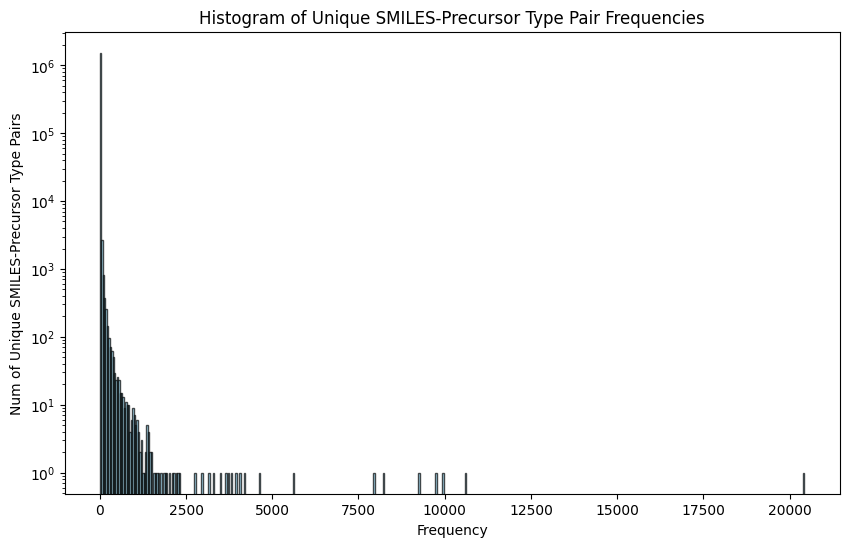

In [49]:
# Concatenate SMILES and precursor type columns from all datasets
smiles_prec_type = pd.concat([df[['smiles', 'prec_type']] for df in smarts_dict.values()])

# Compute frequency of each unique SMILES-precursor type pair
smiles_prec_type_frequency = smiles_prec_type.value_counts().reset_index(name='count')

# Plot a histogram of the frequencies
plt.figure(figsize=(10, 6))
plt.hist(smiles_prec_type_frequency['count'], bins=500, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Histogram of Unique SMILES-Precursor Type Pair Frequencies')
plt.xlabel('Frequency')
plt.ylabel('Num of Unique SMILES-Precursor Type Pairs')
plt.yscale('log')  # Use log scale for better visualization
plt.show()

In [54]:
# Count how many SMILES have frequency more than the specified thresholds
thresholds = [1,2,3,4,5,10, 20, 25, 50, 100]

print("SMILES frequency analysis:")
print(f"Total unique SMILES: {len(smiles_frequency)}")
print()

for threshold in thresholds:
    count = (smiles_frequency >= threshold).sum()
    percentage = (count / len(smiles_frequency)) * 100
    print(f"SMILES with frequency >= {threshold}: {count} ({percentage:.2f}%)")

SMILES frequency analysis:
Total unique SMILES: 1532340

SMILES with frequency >= 1: 1532340 (100.00%)
SMILES with frequency >= 2: 927557 (60.53%)
SMILES with frequency >= 3: 264866 (17.29%)
SMILES with frequency >= 4: 207571 (13.55%)
SMILES with frequency >= 5: 92883 (6.06%)
SMILES with frequency >= 10: 31831 (2.08%)
SMILES with frequency >= 20: 12066 (0.79%)
SMILES with frequency >= 25: 8990 (0.59%)
SMILES with frequency >= 50: 3897 (0.25%)
SMILES with frequency >= 100: 1748 (0.11%)


In [56]:
# Function to compute SMILES frequency analysis for a dataset
def compute_smiles_frequency_analysis(smiles_frequency, thresholds):
    results = []
    total_unique_smiles = len(smiles_frequency)
    for threshold in thresholds:
        count = (smiles_frequency >= threshold).sum()
        percentage = (count / total_unique_smiles) * 100
        results.append({'Threshold': threshold, 'Count': count, 'Percentage': f"{percentage:.2f}%"})
    return pd.DataFrame(results)

# Compute frequency for train, val, and test datasets
train_smiles_frequency = smarts_train_df['smiles'].value_counts()
val_smiles_frequency = smarts_val_df['smiles'].value_counts()
test_smiles_frequency = smarts_test_df['smiles'].value_counts()

thresholds = [1, 2, 3, 4, 5, 10, 20, 25, 50, 100]

train_results = compute_smiles_frequency_analysis(train_smiles_frequency, thresholds)
val_results = compute_smiles_frequency_analysis(val_smiles_frequency, thresholds)
test_results = compute_smiles_frequency_analysis(test_smiles_frequency, thresholds)

# Combine results into a single table
combined_results = pd.concat(
    [train_results.set_index('Threshold'), 
     val_results.set_index('Threshold'), 
     test_results.set_index('Threshold')], 
    axis=1, 
    keys=['Train', 'Val', 'Test']
)

# Display the combined results
combined_results

Train                Val               Test           
            Count Percentage   Count Percentage   Count Percentage
Threshold                                                         
1          972472    100.00%  362962    100.00%  389129    100.00%
2          576622     59.29%  205119     56.51%  220991     56.79%
3          155019     15.94%   49031     13.51%   51805     13.31%
4          120516     12.39%   38132     10.51%   40615     10.44%
5           51506      5.30%   14861      4.09%   16209      4.17%
10          17712      1.82%    4911      1.35%    5035      1.29%
20           6720      0.69%    1896      0.52%    1931      0.50%
25           5046      0.52%    1426      0.39%    1461      0.38%
50           2203      0.23%     574      0.16%     589      0.15%
100           948      0.10%     228      0.06%     242      0.06%

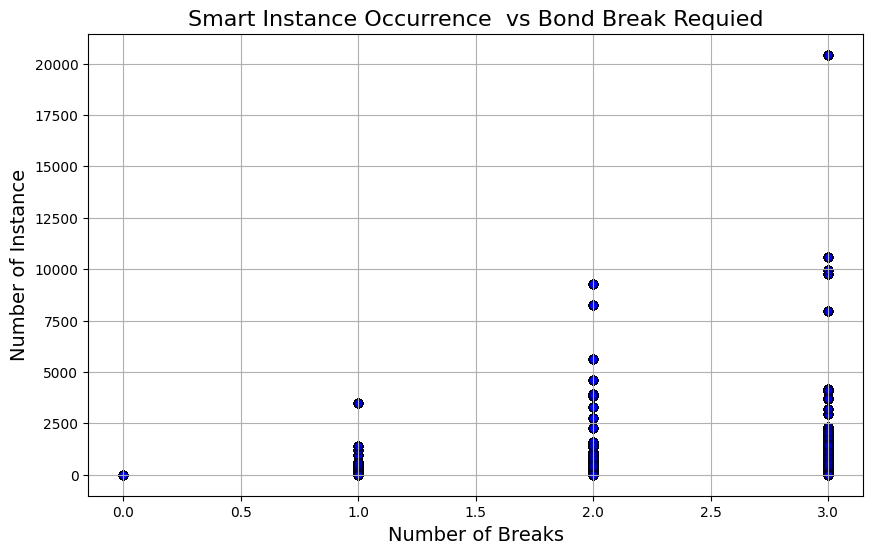

In [36]:
plt.figure(figsize=(10, 6))

# Scatter plot for count vs break
plt.scatter(smarts_train_df['break'], smarts_train_df['count'], alpha=0.1, color='blue', edgecolor='black')

# Add labels and title
plt.title('Smart Instance Occurrence  vs Bond Break Requied', fontsize=16)
plt.xlabel('Number of Breaks', fontsize=14)
plt.ylabel('Number of Instance', fontsize=14)

# Show the plot
plt.grid(True)
plt.show()

## NL Smarts

In [37]:
nl_smarts_train_fp = "../../data/smarts/fraggnn_d3_ma_mi/nl_smarts_train.csv"
nl_smarts_train_df = pd.read_csv(nl_smarts_train_fp)

nl_smarts_val_fp = "../../data/smarts/fraggnn_d3_ma_mi/nl_smarts_val.csv"
nl_smarts_val_df = pd.read_csv(nl_smarts_val_fp)

nl_smarts_test_fp = "../../data/smarts/fraggnn_d3_ma_mi/nl_smarts_test.csv"
nl_smarts_test_df = pd.read_csv(nl_smarts_test_fp)


In [38]:
nl_smarts_dict = {
    'train': nl_smarts_train_df,
    'val': nl_smarts_val_df,
    'test': nl_smarts_test_df
}
get_smarts_df_stats(nl_smarts_dict)

,dataset,prec_type,formula_count,smiles_count,unique_formulas,unique_smiles
0,train,[M+H]+,31696607,31696607,120686,543844
1,train,OVERLAP,0,0,0,0
2,val,[M+H]+,10886151,10886151,63003,201646
3,val,OVERLAP,0,0,0,0
4,test,[M+H]+,10970143,10970143,65507,208089
5,test,OVERLAP,0,0,0,0


In [39]:
# Concatenate SMILES from all datasets
nl_all_smiles = pd.concat([df['smiles'] for df in nl_smarts_dict.values()])

# Compute frequency of each unique SMILES
nl_smiles_frequency = nl_all_smiles.value_counts()

# Display the result
nl_smiles_frequency

smiles
*C                               6087906
*O                               5838272
*=O                              5724341
*c*                              1641458
*N                                937849
                                  ...   
*c(ccc(Cl)c(*)Cl)NC(=O)NC1CC1          1
*cc(cc(Cl)c(*)Cl)NC(=O)NC1CC1          1
*c(cc(Cl)c(*)Cl)NC(=O)NC1CC1           1
*cc(Cl)c(Cl)cc(*)NC(=O)NC1CC1          1
*c1cc(NC(=O)NC2CC2)ccc1Cl              1
Name: count, Length: 853672, dtype: int64

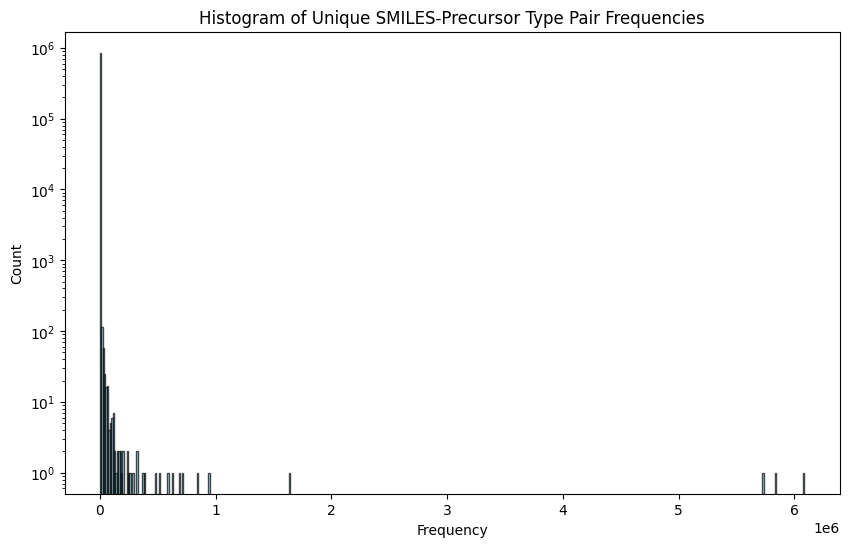

In [40]:
# Concatenate SMILES and precursor type columns from all datasets
nl_smiles_prec_type = pd.concat([df[['smiles', 'prec_type']] for df in nl_smarts_dict.values()])

# Compute frequency of each unique SMILES-precursor type pair
nl_smiles_prec_type_frequency = nl_smiles_prec_type.value_counts().reset_index(name='count')

# Plot a histogram of the frequencies
plt.figure(figsize=(10, 6))
plt.hist(nl_smiles_prec_type_frequency['count'], bins=500, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Histogram of Unique SMILES-Precursor Type Pair Frequencies')
plt.xlabel('Frequency')
plt.ylabel('Count')
plt.yscale('log')  # Use log scale for better visualization
plt.show()

In [41]:
# Find the intersection of unique SMILES in both series
duplicated_smiles = set(all_smiles.unique()) & set(nl_all_smiles.unique())

# Count the number of duplicated SMILES
num_duplicated_smiles = len(duplicated_smiles)

print(f"Number of unique SMILES in all datasets: {len(all_smiles.unique())}")
print(f"Number of unique SMILES in NL datasets: {len(nl_all_smiles.unique())}")
print(f"Number of duplicated SMILES: {num_duplicated_smiles}")
duplicated_smiles

Number of unique SMILES in all datasets: 1532340
Number of unique SMILES in NL datasets: 853672
Number of duplicated SMILES: 261034


{'*C(=O)C=CC(O)CCCC(C)CC=CC1C(O)C(=C)C(C)C2C(Cc3ccccc3)NC(=O)C12*',
 '*c1c2c(c(O)c3c(O)cccc13)C(=O)C1(O)C(=O)C(C(N)=O)C(=O)C(N(C)C)C1C2',
 '*CC1C(C(*)*)CCC2=Cc3oncc3CC21C',
 '*c1ccc2nnc(C)n2n1',
 '*c1c(OC)cc(C)c(C=CC(C)=CC=CC(C)=CC(=O)OCC)c1C',
 '*nc1ccc(C(=O)O)cc1c1c(*)CCC1',
 '*CC(*)C(C*)CC',
 '*ccc(*)cc(-c1ccc(OC)c(OC)c1)c(*)=O',
 '*C=C1C(C)CCCC1(C)CC(*)*',
 '*=C(NC1C(=O)N2C1SC(C)(C)C2C(=O)O)C(C(=O)O)c1ccsc1',
 '*CCc(*)cc(c*)S(=O)(=O)N(C)C',
 '*Cc1cc(C(=O)O)sc1*',
 '*ncc(*)-c1[nH]c2ccccc2c1C=O',
 '*Cc1c(*)cc2n(c1=O)Cc1c-2nc2ccc(O)cc2c1CC',
 '*C1(F)C2CNCC21',
 '*cc(Cl)cc(*)nc(*)-c1cc(N)ccc1O',
 '*=S(=O)(Nc1ccc(CCC)cc1C(=O)O)c1ccccc1',
 '*C(=O)C(C=C(*)C)OC',
 '*=Cc(*)c1ccccc1c*',
 '*CCC=C(CC=CC(*)(C)C)C(=O)O',
 '*C(*)CCCCCCCCCCC',
 '*CCC(C=*)N*',
 '*cc(C)nc(c*)-c1[nH]c(C(C)(C)C)nc1-c1ccc2c(c1)OCO2',
 '*nc(=O)n(C)c1nc(Br)[nH]c1*',
 '*c1c2nc3c(C(=O)O)cccc3oc-2cc(=O)c1N',
 '*OC(*)c1c(C)coc1CC(=*)C',
 '*C1CC(C)C(=O)C1(C)CC(O)C(*)(F)C1(C)C=CC(=O)CC1=*',
 '*cc(*)-c1cccc2c1Sc1ccccc1S2',
 '*C